# Project 1: Bank Marketing – Predicting Term-Deposit Subscription

**Task:** Predict whether a customer will subscribe to a term deposit, to support selecting customers for a telephone marketing campaign.

**Data source:** `bank-additional-full.csv`, UCI Machine Learning Repository, *Bank Marketing* dataset. S. Moro, P. Cortez and P. Rita (2014), "A Data-Driven Approach to Predict the Success of Bank Telemarketing", *Decision Support Systems* 62, 22–31. 41,188 calls by a Portuguese bank, May 2008 to November 2010.

**Contents:** 1. Loading and inspecting · 2. Data preparation · 3. Baseline and model comparison · 4. Hold-out test and robustness check · 5. Ranking of approaches · 6. Decision threshold · 7. Conclusions and limitations

**To run:** put `bank-additional-full.csv` in the same folder as this notebook and install the packages in `requirements.txt`.

## 1. Loading and inspecting the data

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("bank-additional-full.csv", sep=";")   # this file uses ; as separator
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["y"].value_counts(normalize=True).round(3))
df.head()

(41188, 21)
Missing values: 0
Duplicate rows: 12

Target distribution:
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**Observations:**
- 41,188 customers, 20 input variables and the target `y`
- no blank cells and 12 duplicate rows
- only 11.3% subscribed ("yes"): the classes are heavily imbalanced
- a majority-class baseline that predicts "no" for everyone is 88.7% accurate but identifies no subscribers, so accuracy is a misleading measure for this task

### Hidden missing values and special codes
The data has no blank cells, but missing information is recorded as the text "unknown", and `pdays = 999` means the customer was never contacted before.

In [14]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("y")
print("Number of 'unknown' values per column:")
print((df[cat_cols] == "unknown").sum().loc[lambda s: s > 0])
print("\nShare of customers never previously contacted (pdays = 999):",
      round((df["pdays"] == 999).mean(), 3))

Number of 'unknown' values per column:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

Share of customers never previously contacted (pdays = 999): 0.963


### Subscription rate by key variables

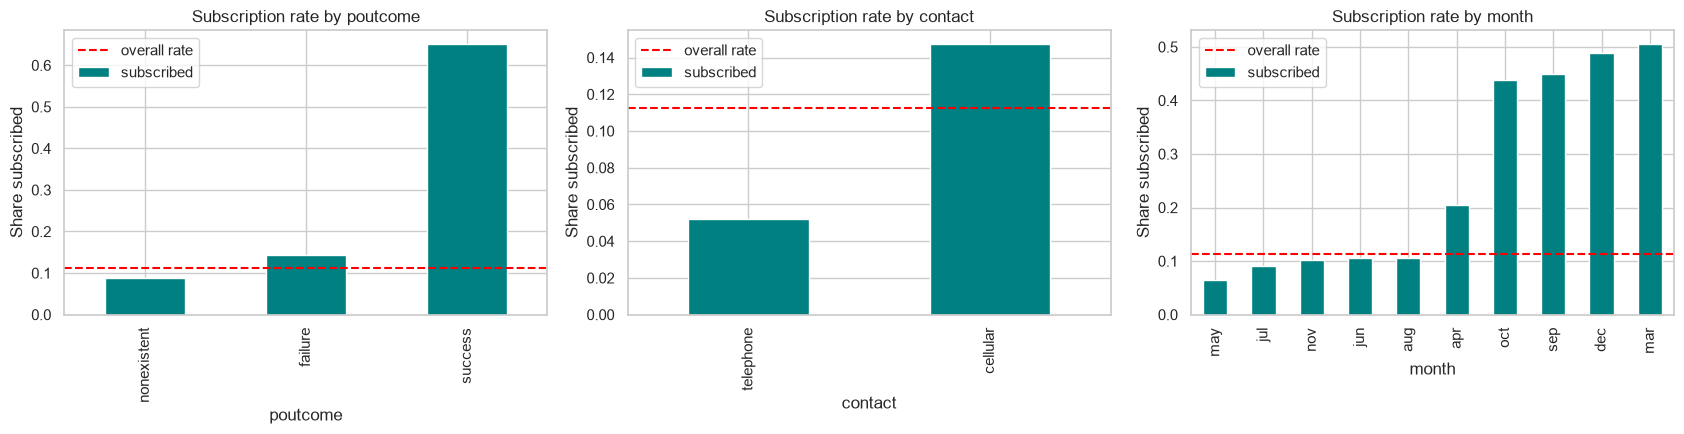

In [15]:
df["subscribed"] = (df["y"] == "yes").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    df.groupby(col)["subscribed"].mean().sort_values().plot(kind="bar", ax=ax, color="teal")
    ax.axhline(df["subscribed"].mean(), color="red", linestyle="--", label="overall rate")
    ax.set(title=f"Subscription rate by {col}", ylabel="Share subscribed")
    ax.legend()
plt.tight_layout()
plt.show()

In [16]:
df.groupby("y")["duration"].median()

y
no     163.5
yes    449.0
Name: duration, dtype: float64

**Observations:**

- "unknown" is used instead of blank cells: default 8,597, education 1,731, housing/loan 990 each, job 330, marital 80
- 96.3% of customers were never contacted in a previous campaign (pdays = 999)
- previous campaign outcome: "success" customers subscribe about 65%, against about 9–14% for the rest
- contact type: cellular about 15%, telephone about 5% (overall rate 11.3%)
- month: March, September, October and December above 40%; May lowest (about 6%)
- call duration: median 449 s for "yes" against 164 s for "no", but it's only known after the call ends

In [17]:
# The rows are stored in date order (May 2008 to Nov 2010).
# Split the file into 10 equal blocks and look at how the subscription rate and euribor change over time.
block = np.arange(len(df)) * 10 // len(df)
time_view = pd.DataFrame({"Subscription rate": df["subscribed"].groupby(block).mean(),
                          "Mean euribor3m": df["euribor3m"].groupby(block).mean()})
time_view.index.name = "Block (1/10 of file, oldest first)"
display(time_view.round(3))

macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print("Correlation between the economic indicators:")
display(df[macro].corr().round(2))
print("Values of 'default':")
print(df["default"].value_counts())

,Subscription rate,Mean euribor3m
"Block (1/10 of file, oldest first)",,
0,0.028,4.857
1,0.035,4.859
2,0.042,4.941
3,0.066,4.961
4,0.062,4.965
5,0.055,4.845
6,0.102,3.370
7,0.120,1.354
8,0.157,1.260


Correlation between the economic indicators:


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.20,0.06,1.00,0.28,0.10
euribor3m,0.97,0.69,0.28,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


Values of 'default':
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64


**Observations (time order, economic indicators, `default`):**

- the subscription rate rises from about 3% in the oldest tenth of the file to about 46% in the newest tenth, while the 3-month euribor rate falls from about 4.9 to 0.8. The customer mix and the economy changed over the campaign period
- the economic indicators are strongly correlated with each other (euribor3m vs emp.var.rate 0.97, euribor3m vs nr.employed 0.95). They describe the period of the call, not the customer
- `default` has only 3 "yes" values; nearly everyone is "no" or "unknown", so it carries little information beyond "unknown"

**Implication:** a random train/test split mixes old and new periods and may be optimistic about how the model will perform on a *future* campaign. Section 4 adds a time-ordered check.

## 2. Data preparation

- **Duplicates:** 12 exact duplicate rows removed.
- **`duration` dropped:** call length is only known after the call ends, so it cannot be used to select customers before calling. Including it would be data leakage (also noted in the dataset documentation, Moro et al., 2014).
- **"unknown" values:** kept as their own category instead of being removed or imputed. Removing them would lose about a quarter of the rows (mostly through `default`), and "unknown" may itself carry information (e.g. customers unwilling to disclose default status).
- **`pdays`:** replaced by a yes/no flag `previously_contacted`, because 999 is a code, not a number of days.
- **Economic indicators:** kept. They are strongly correlated, which does not hurt tree models; logistic regression in scikit-learn uses L2 regularisation by default, which keeps the coefficients stable. Their dependence on time is tested in Section 4.
- **Class imbalance (11.3% yes):** no resampling. Models are compared on ranking metrics (ROC-AUC, PR-AUC) that do not depend on a threshold, and the imbalance is then handled by choosing the decision threshold deliberately (Section 6).
- **Encoding and scaling:** categorical variables are one-hot encoded and numeric variables standardised, inside a pipeline fitted only on training data, so no information leaks from the test set.
- **Split:** stratified 80/20 train/test, so both sets keep the 11.3% "yes" rate.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data = df.drop(columns=["subscribed"]).drop_duplicates().reset_index(drop=True)
data["previously_contacted"] = (data["pdays"] != 999).astype(int)
data = data.drop(columns=["duration", "pdays"])
print("Rows after removing duplicates:", len(data))

X = data.drop(columns="y")
y = (data["y"] == "yes").astype(int)   # 1 = subscribed, 0 = not

cat_features = X.select_dtypes(exclude="number").columns.tolist()
num_features = X.select_dtypes(include="number").columns.tolist()

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("num", StandardScaler(), num_features)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Yes rate in train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Rows after removing duplicates: 41176
Train: (32940, 19)  Test: (8236, 19)
Yes rate in train / test: 0.113 / 0.113


## 3. Majority-class baseline and model comparison

The **majority-class baseline** predicts "no" for every customer. Because the data is imbalanced, accuracy is misleading, so models are compared with:

- **ROC-AUC:** how well the model ranks subscribers above non-subscribers (0.5 = random, 1 = perfect)
- **PR-AUC (average precision):** focuses on the rare "yes" class; the baseline equals the yes rate (about 0.11)

Three approaches are compared with **5-fold stratified cross-validation** on the training set:

| Model | Why included |
|---|---|
| Logistic regression | Simple, interpretable, gives well-behaved probabilities |
| Random forest | Captures non-linear effects and interactions, robust |
| Gradient boosting (histogram-based) | Often strongest on tabular data, fast on large datasets |

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Majority baseline": make_pipeline(preprocess, DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_pipeline(preprocess, LogisticRegression(max_iter=2000)),
    "Random forest": make_pipeline(preprocess, RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient boosting": make_pipeline(preprocess, HistGradientBoostingClassifier(
        random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"Accuracy": "accuracy", "ROC_AUC": "roc_auc", "PR_AUC": "average_precision"}

rows, fold_pr = [], {}
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    fold_pr[name] = s["test_PR_AUC"]          # keep the score of every fold for a paired comparison
    rows.append({"Model": name,
                 "Accuracy": s["test_Accuracy"].mean(),
                 "ROC-AUC": s["test_ROC_AUC"].mean(),
                 "ROC-AUC (std)": s["test_ROC_AUC"].std(),
                 "PR-AUC": s["test_PR_AUC"].mean(),
                 "PR-AUC (std)": s["test_PR_AUC"].std(),
                 "Fit time (s)": s["fit_time"].mean()})

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results

,Accuracy,ROC-AUC,ROC-AUC (std),PR-AUC,PR-AUC (std),Fit time (s)
Model,,,,,,
Majority baseline,0.887,0.500,0.000,0.113,0.000,0.136
Logistic regression,0.900,0.790,0.007,0.451,0.014,0.678
Random forest,0.901,0.794,0.007,0.467,0.013,3.406
Gradient boosting,0.901,0.800,0.008,0.465,0.016,0.980


**Cross-validation results:**

- Majority baseline: accuracy 0.887 but ROC-AUC 0.500 and PR-AUC 0.113, so it has no ability to find subscribers
- ROC-AUC: gradient boosting 0.800, random forest 0.794, logistic regression 0.790 (std about 0.007)
- PR-AUC: random forest 0.467, gradient boosting 0.465, logistic regression 0.451 (std about 0.014)
- all three models beat the baseline clearly; the differences between them are small (about 1–2 standard deviations)
- in testing, gradient boosting trained about 5 times faster than random forest (see fit time); logistic regression is the easiest to interpret

In [20]:
# Paired comparison: the folds are the same for every model, so we can compare fold by fold
folds = pd.DataFrame(fold_pr).drop(columns="Majority baseline")
folds.index = [f"Fold {i+1}" for i in range(len(folds))]
folds.round(3)

,Logistic regression,Random forest,Gradient boosting
Fold 1,0.459,0.468,0.466
Fold 2,0.451,0.468,0.468
Fold 3,0.425,0.443,0.435
Fold 4,0.457,0.481,0.485
Fold 5,0.466,0.474,0.472


**Fold-by-fold PR-AUC:** random forest scores higher than logistic regression in all 5 folds, so its small advantage is consistent rather than luck. Random forest and gradient boosting are effectively tied (each wins some folds).

## 4. Final evaluation on the hold-out test set
Each model is trained on the full training set and evaluated once on the untouched test set.

In [21]:
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay

probs, test_rows = {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    probs[name] = model.predict_proba(X_test)[:, 1]   # predicted probability of "yes"
    test_rows.append({"Model": name,
                      "ROC-AUC": roc_auc_score(y_test, probs[name]),
                      "PR-AUC": average_precision_score(y_test, probs[name])})

pd.DataFrame(test_rows).set_index("Model").round(3)

,ROC-AUC,PR-AUC
Model,,
Majority baseline,0.500,0.113
Logistic regression,0.801,0.453
Random forest,0.804,0.484
Gradient boosting,0.812,0.491


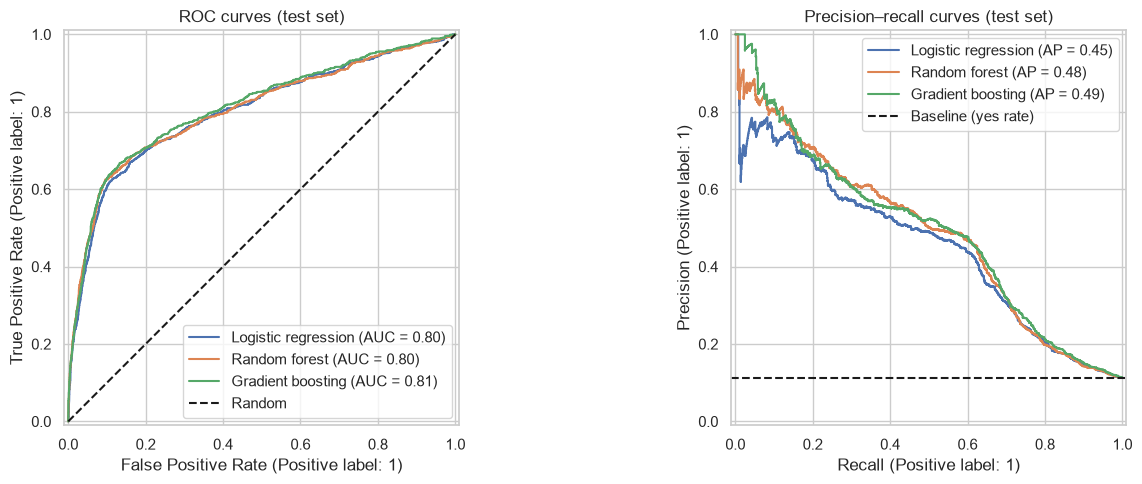

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in ["Logistic regression", "Random forest", "Gradient boosting"]:
    RocCurveDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_title("ROC curves (test set)")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (yes rate)")
axes[1].set_title("Precision–recall curves (test set)")
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

**Test-set results:**

- ROC-AUC: gradient boosting 0.812, random forest 0.804, logistic regression 0.801
- PR-AUC: gradient boosting 0.491, random forest 0.484, logistic regression 0.453
- the test results agree with the cross-validation ranking under a random split (a time-ordered check follows below)
- on the precision–recall curve, logistic regression is noticeably weaker for the customers the models are most confident about (left side of the plot)

### Robustness check: time-ordered split

The random split lets the model see every time period during training. In practice the bank would train on past campaigns and score the *next* one. Here we train on the oldest 80% of the rows and test on the newest 20%.

In [23]:
from sklearn.base import clone

n_train = int(len(X) * 0.8)                       # rows are in date order
X_old, X_new = X.iloc[:n_train], X.iloc[n_train:]
y_old, y_new = y.iloc[:n_train], y.iloc[n_train:]
print("Yes rate, older 80%:", round(y_old.mean(), 3), "  newer 20%:", round(y_new.mean(), 3))
print("euribor3m range, older:", X_old["euribor3m"].min(), "-", X_old["euribor3m"].max(),
      "  newer:", X_new["euribor3m"].min(), "-", X_new["euribor3m"].max())

time_rows = []
for name, model in models.items():
    m = clone(model).fit(X_old, y_old)            # clone = fresh copy, so earlier fitted models are untouched
    p_new = m.predict_proba(X_new)[:, 1]
    time_rows.append({"Model": name,
                      "ROC-AUC": roc_auc_score(y_new, p_new),
                      "PR-AUC": average_precision_score(y_new, p_new),
                      "PR-AUC baseline (yes rate)": y_new.mean()})
pd.DataFrame(time_rows).set_index("Model").round(3)

Yes rate, older 80%: 0.064   newer 20%: 0.308
euribor3m range, older: 1.299 - 5.045   newer: 0.634 - 1.299


,ROC-AUC,PR-AUC,PR-AUC baseline (yes rate)
Model,,,
Majority baseline,0.500,0.308,0.308
Logistic regression,0.748,0.527,0.308
Random forest,0.742,0.542,0.308
Gradient boosting,0.631,0.419,0.308


**Time-ordered results:**

- all three models still beat the baseline, but the gap between them changes: logistic regression (ROC-AUC 0.75) and random forest (0.74) hold up, while gradient boosting drops to about 0.63
- the newest 20% of calls happened at euribor rates (0.63–1.30) that are lower than any rate in the training period. Tree models cannot extrapolate beyond values they have seen, and gradient boosting relies heavily on these indicators, so it suffers most
- the yes rate also jumps from about 6% to 31%, so PR-AUC values are not comparable with the random-split numbers

**Conclusion:** the random-split ranking is not robust to a change in economic conditions. The ranking below takes both checks into account.

## 5. Ranking of the three approaches

| Rank | Approach | Evidence | Strengths | Weaknesses |
|---|---|---|---|---|
| **1** | **Random forest** | CV PR-AUC 0.467 (beats logistic regression in 5/5 folds); test PR-AUC 0.484; best PR-AUC on the time-ordered split (0.54) | Consistently near the top under both random and time-ordered validation; handles non-linear effects and interactions | Slowest to train; less interpretable |
| **2** | **Logistic regression** | CV PR-AUC 0.451; test 0.453; best ROC-AUC on the time-ordered split (0.75) | Most stable under changing conditions; fast; coefficients are easy to explain to the marketing team | Weakest among the most confident predictions (left of the PR curve) |
| **3** | **Gradient boosting** | Best on random CV (ROC-AUC 0.800) and random test (0.812), but worst on the time-ordered split (0.63) | Fast; strongest when future data looks like the past | Fragile when economic conditions move outside the training range |

**Justification:** PR-AUC is the main criterion because the business goal is to find the rare subscribers among people we call. Under the random split the three models are within about 1–2 standard deviations of each other, so that split alone cannot separate them. The time-ordered check is closer to real use (scoring a future campaign) and separates them clearly. Random forest is the only model that is near the top in both checks, so it is ranked first and used for the threshold analysis. Logistic regression is a close, more interpretable second and would be a reasonable choice if explainability matters most.

## 6. Choosing a decision threshold

We use **random forest** (ranked first). To avoid tuning on the test set, the threshold is chosen using **out-of-fold predictions on the training set** (each training customer is scored by a model that did not see them), and then checked once on the test set.

- **Precision:** of the customers we call, the share who subscribe
- **Recall:** of all actual subscribers, the share we reach
- **Unnecessary calls** = false positives; **missed subscribers** = false negatives

In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

chosen = "Random forest"
p_oof = cross_val_predict(models[chosen], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
p_test = probs[chosen]

def threshold_table(y_true, p, cuts=(0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5)):
    rows = []
    for t in cuts:
        pred = (p >= t).astype(int)
        rows.append({"Threshold": t,
                     "Customers called": pred.sum(),
                     "% of list called": 100 * pred.mean(),
                     "Precision": precision_score(y_true, pred),
                     "Recall": recall_score(y_true, pred),
                     "Unnecessary calls": ((pred == 1) & (y_true == 0)).sum(),
                     "Missed subscribers": ((pred == 0) & (y_true == 1)).sum()})
    return pd.DataFrame(rows).set_index("Threshold").round(3)

print("Training set, out-of-fold predictions (used to CHOOSE the threshold):")
display(threshold_table(y_train, p_oof))
print("Test set (used only to CONFIRM the choice):")
display(threshold_table(y_test, p_test))

Training set, out-of-fold predictions (used to CHOOSE the threshold):


,Customers called,% of list called,Precision,Recall,Unnecessary calls,Missed subscribers
Threshold,,,,,,
0.05,18579,56.403,0.168,0.843,15451,583
0.10,8154,24.754,0.306,0.673,5655,1212
0.15,5660,17.183,0.399,0.609,3400,1451
0.20,4960,15.058,0.437,0.584,2794,1545
0.25,4414,13.400,0.459,0.546,2387,1684
0.30,3759,11.412,0.489,0.496,1919,1871
0.40,2320,7.043,0.575,0.359,986,2377
0.50,1431,4.344,0.655,0.253,493,2773


Test set (used only to CONFIRM the choice):


,Customers called,% of list called,Precision,Recall,Unnecessary calls,Missed subscribers
Threshold,,,,,,
0.05,4638,56.314,0.171,0.855,3845,135
0.10,2028,24.624,0.320,0.699,1379,279
0.15,1413,17.156,0.417,0.635,824,339
0.20,1229,14.922,0.461,0.611,662,361
0.25,1099,13.344,0.487,0.577,564,393
0.30,909,11.037,0.505,0.495,450,469
0.40,562,6.824,0.596,0.361,227,593
0.50,353,4.286,0.654,0.249,122,697


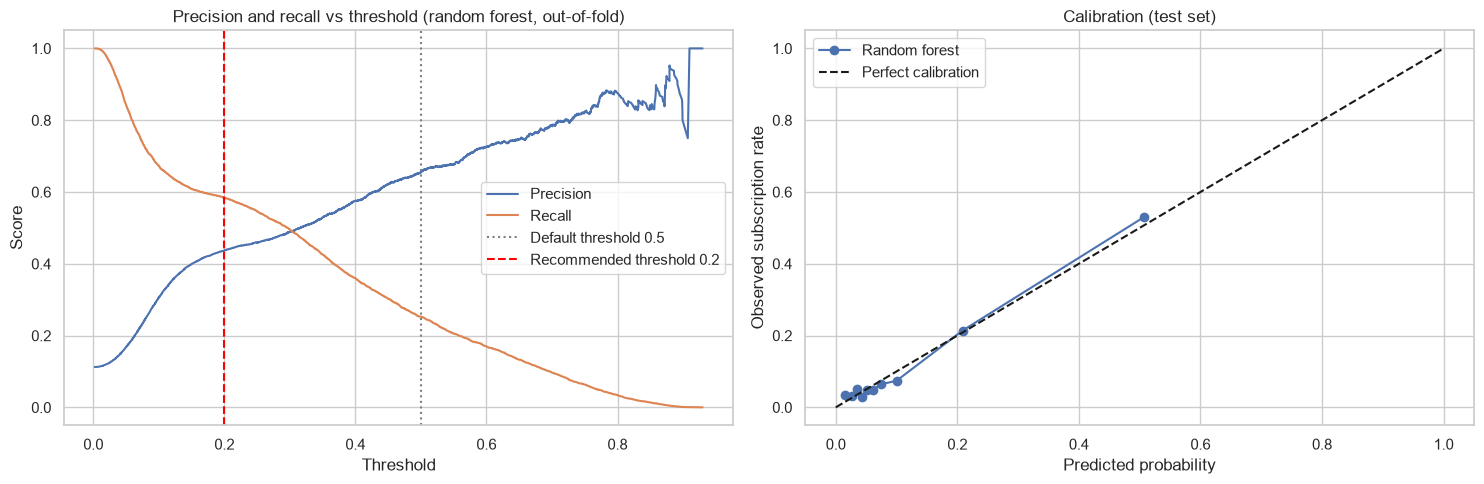

In [25]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

prec, rec, thr = precision_recall_curve(y_train, p_oof)
axes[0].plot(thr, prec[:-1], label="Precision")
axes[0].plot(thr, rec[:-1], label="Recall")
axes[0].axvline(0.5, color="grey", linestyle=":", label="Default threshold 0.5")
axes[0].axvline(0.2, color="red", linestyle="--", label="Recommended threshold 0.2")
axes[0].set(xlabel="Threshold", ylabel="Score",
            title="Precision and recall vs threshold (random forest, out-of-fold)")
axes[0].legend()

# Calibration: are the predicted probabilities honest? Needed for the cost rule below.
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
axes[1].plot(mean_pred, frac_pos, "o-", label="Random forest")
axes[1].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[1].set(xlabel="Predicted probability", ylabel="Observed subscription rate",
            title="Calibration (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Linking the threshold to costs

If one call costs **C** and a subscription is worth **V** to the bank, calling a customer is worthwhile when their probability of subscribing is above **C / V**. This only works if the predicted probabilities are honest; the calibration plot shows the random forest's probabilities lie close to the diagonal, so the rule is reasonable. The cell below finds the threshold that maximises net value on the out-of-fold predictions for a few assumed value-to-cost ratios.

In [26]:
cut_grid = np.round(np.arange(0.02, 0.61, 0.01), 2)
rows = []
for ratio in [3, 5, 10, 20]:                       # assumed value of a subscriber / cost of a call
    net = [ratio * ((p_oof >= t) & (y_train == 1)).sum() - (p_oof >= t).sum() for t in cut_grid]
    best_t = cut_grid[int(np.argmax(net))]
    rows.append({"Value / cost ratio": ratio, "Break-even probability (1/ratio)": round(1 / ratio, 3),
                 "Best threshold (out-of-fold)": best_t})
pd.DataFrame(rows).set_index("Value / cost ratio")

,Break-even probability (1/ratio),Best threshold (out-of-fold)
Value / cost ratio,,
3,0.333,0.31
5,0.200,0.21
10,0.100,0.12
20,0.050,0.05


### Recommendation

**Recommended threshold: 0.20** (instead of the default 0.5).

On the test set (928 actual subscribers out of 8,236 customers) this means:

| Threshold | Calls | % of list | Precision | Recall | Unnecessary calls | Missed subscribers |
|---|---|---|---|---|---|---|
| 0.10 | 2,028 | 24.6% | 0.32 | 0.70 | 1,379 | 279 |
| **0.20** | **1,229** | **14.9%** | **0.46** | **0.61** | **662** | **361** |
| 0.30 | 909 | 11.0% | 0.51 | 0.50 | 450 | 469 |
| 0.50 (default) | 353 | 4.3% | 0.65 | 0.25 | 122 | 697 |

**The trade-off:**

- at 0.20 the bank calls about 15% of the list and reaches about 61% of all subscribers. Almost half of the calls succeed, about four times the 11.3% success rate of calling everyone
- the default 0.5 makes very few unnecessary calls but misses three out of four subscribers, which wastes most of the opportunity
- going down to 0.10 reaches 9% more subscribers but more than doubles the unnecessary calls (662 → 1,379)
- the out-of-fold and test tables agree closely, so the choice does not depend on one lucky split
- 0.20 is also the cost-optimal threshold when a subscriber is worth about five times the cost of a call. If the bank's real value-to-cost ratio is higher (e.g. 10 or more), a lower threshold (about 0.10) pays off; if call-centre capacity is the binding limit, the bank should simply call the top-ranked customers until capacity runs out

The threshold should be reviewed with the marketing team's actual costs and capacity, and re-checked whenever economic conditions change

## 7. Conclusions and limitations

**Conclusions**

- all three models clearly beat the majority-class baseline, which is 88.7% accurate but finds no subscribers
- random forest is recommended: it is consistently near the top under both random and time-ordered validation
- with a threshold of 0.20 the bank can reach about 60% of subscribers by calling about 15% of customers

**Limitations**

- **Changing conditions:** the yes rate and the economic indicators changed a lot over 2008–2010. Performance on a future campaign may be lower than the random-split scores suggest; the model should be monitored and retrained regularly
- **No hyperparameter tuning:** sensible default settings were used. Tuning could improve each model slightly but is unlikely to change the overall conclusions given the small differences between models
- **Prediction, not cause:** the model finds customers who are *likely* to subscribe; it does not show that calling them *causes* the subscription
- **Responsible use:** the model uses personal attributes such as age, job and marital status. Before deployment the bank should check that selection rates are not unfairly skewed against particular groups and that use of the data meets data-protection rules (e.g. GDPR in Portugal)